In [21]:
%pip install sqlalchemy pymysql pandas

/home/sanskar/Downloads/python/Data_analysis/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [22]:
import pandas as pd
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

In [23]:
DB_USER = "root"
DB_PASSWORD = "toor"
DB_HOST = "localhost"
DB_PORT = 3306
DB_NAME = "ecommerce_etl"

In [24]:
connection_url = URL.create(
    drivername="mysql+pymysql",
    username=DB_USER,
    password=DB_PASSWORD,
    host=DB_HOST,
    port=DB_PORT,
    database=DB_NAME
)

engine = create_engine(
    connection_url,
    pool_pre_ping=True
)

print("SQLAlchemy engine created successfully!")

SQLAlchemy engine created successfully!


In [25]:
import pandas as pd
from pathlib import Path

PROCESSED_DIR = Path("../data/processed")

customers = pd.read_csv(
    PROCESSED_DIR / "customers_cleaned.csv"
)

baskets = pd.read_csv(
    PROCESSED_DIR / "baskets_cleaned.csv"
)

In [26]:
print("Customers shape:", customers.shape)
print("Baskets shape:", baskets.shape)

display(customers.head())
display(baskets.head())

Customers shape: (20000, 4)
Baskets shape: (15000, 4)


,customer_id,sex,customer_age,tenure
0,9798859,Male,44.0,93
1,11413563,Male,36.0,65
2,818195,Male,35.0,129
3,12049009,Male,33.0,58
4,10083045,Male,42.0,88


,customer_id,product_id,basket_date,basket_count
0,42366585,41475073,2019-06-19,2
1,35956841,43279538,2019-06-19,2
2,26139578,31715598,2019-06-19,3
3,3262253,47880260,2019-06-19,2
4,20056678,44747002,2019-06-19,2


In [27]:
print(customers.dtypes)


customer_id       int64
sex                 str
customer_age    float64
tenure            int64
dtype: object


In [28]:
print(baskets.dtypes)

customer_id     int64
product_id      int64
basket_date       str
basket_count    int64
dtype: object


In [29]:
baskets["basket_date"] = pd.to_datetime(
    baskets["basket_date"],)

In [30]:
print(baskets.dtypes)

customer_id              int64
product_id               int64
basket_date     datetime64[us]
basket_count             int64
dtype: object


In [31]:
print("Missing or invalid basket dates:",
      baskets["basket_date"].isna().sum())

Missing or invalid basket dates: 0


# Load the customer data into MySQL

In [32]:
customers.to_sql(
    name="customer_details",
    con=engine,
    if_exists="replace",
    index=False,
    chunksize=1000
)

20000

In [33]:
baskets.to_sql(
    name="basket_details",
    con=engine,
    if_exists="replace",
    index=False,
    chunksize=1000
)

15000

In [ ]:
with engine.connect() as connection:

    customer_count = connection.execute(
        text("SELECT COUNT(*) FROM customer_details")
    ).scalar_one()

    basket_count = connection.execute(
        text("SELECT COUNT(*) FROM basket_details")
    ).scalar_one()

print("Customers in MySQL:", customer_count)
print("Baskets in MySQL:", basket_count)

Customers in MySQL: 20000
Baskets in MySQL: 15000


In [37]:
assert customer_count == len(customers)
assert basket_count == len(baskets)

print("Data load validation passed!")

Data load validation passed!


# Query the data directly from MySQL

In [38]:
query = """
SELECT *
FROM customer_details
LIMIT 10;
"""

customers_from_db = pd.read_sql_query(
    query,
    engine
)

display(customers_from_db)

,customer_id,sex,customer_age,tenure
0,9798859,Male,44.0,93
1,11413563,Male,36.0,65
2,818195,Male,35.0,129
3,12049009,Male,33.0,58
4,10083045,Male,42.0,88
5,11248447,Male,37.0,68
6,819721,Male,46.0,129
7,4713723,Male,35.0,115
8,11141669,Male,36.0,69
9,10844015,Male,37.0,73


In [39]:
query = """
SELECT
    sex,
    COUNT(*) AS customer_count
FROM customer_details
GROUP BY sex
ORDER BY customer_count DESC;
"""

sex_summary = pd.read_sql_query(
    query,
    engine
)

display(sex_summary)

,sex,customer_count
0,Male,15322
1,Female,4669
2,Unknown,9


# Analyze customer age

In [40]:
query = """
SELECT
    COUNT(*) AS total_customers,
    COUNT(customer_age) AS customers_with_age,
    ROUND(AVG(customer_age), 2) AS average_age,
    MIN(customer_age) AS minimum_age,
    MAX(customer_age) AS maximum_age
FROM customer_details;
"""

age_summary = pd.read_sql_query(query, engine)

display(age_summary)

,total_customers,customers_with_age,average_age,minimum_age,maximum_age
0,20000,13293,32.21,3.0,100.0


# Analyze customer tenure

In [41]:
query = """
SELECT
    MIN(tenure) AS minimum_tenure,
    MAX(tenure) AS maximum_tenure,
    ROUND(AVG(tenure), 2) AS average_tenure,
    COUNT(*) AS total_records
FROM customer_details;
"""

tenure_summary = pd.read_sql_query(query, engine)

display(tenure_summary)

,minimum_tenure,maximum_tenure,average_tenure,total_records
0,4,133,44.4,20000


# Find the top 10 products by recorded quantity

In [42]:
query = """
SELECT
    product_id,
    SUM(basket_count) AS total_quantity,
    COUNT(*) AS number_of_records
FROM basket_details
GROUP BY product_id
ORDER BY total_quantity DESC
LIMIT 10;
"""

top_products = pd.read_sql_query(query, engine)

display(top_products)

,product_id,total_quantity,number_of_records
0,43524799,69.0,32
1,31516269,59.0,25
2,39833031,50.0,24
3,46130148,36.0,17
4,34913531,28.0,10
5,3735903,27.0,12
6,40276011,27.0,12
7,6411072,23.0,10
8,42033035,23.0,11
9,39050110,22.0,11


# Analyze basket activity over time

In [43]:
query = """
SELECT
    DATE(basket_date) AS activity_date,
    COUNT(*) AS basket_records,
    SUM(basket_count) AS total_quantity
FROM basket_details
GROUP BY DATE(basket_date)
ORDER BY activity_date;
"""

daily_activity = pd.read_sql_query(query, engine)

display(daily_activity.head(10))

,activity_date,basket_records,total_quantity
0,2019-05-20,518,1114.0
1,2019-05-21,457,977.0
2,2019-05-22,276,593.0
3,2019-05-23,275,600.0
4,2019-05-24,611,1287.0
5,2019-05-25,1162,2473.0
6,2019-05-26,1578,3390.0
7,2019-05-27,1617,3478.0
8,2019-05-28,1213,2708.0
9,2019-05-29,464,1016.0


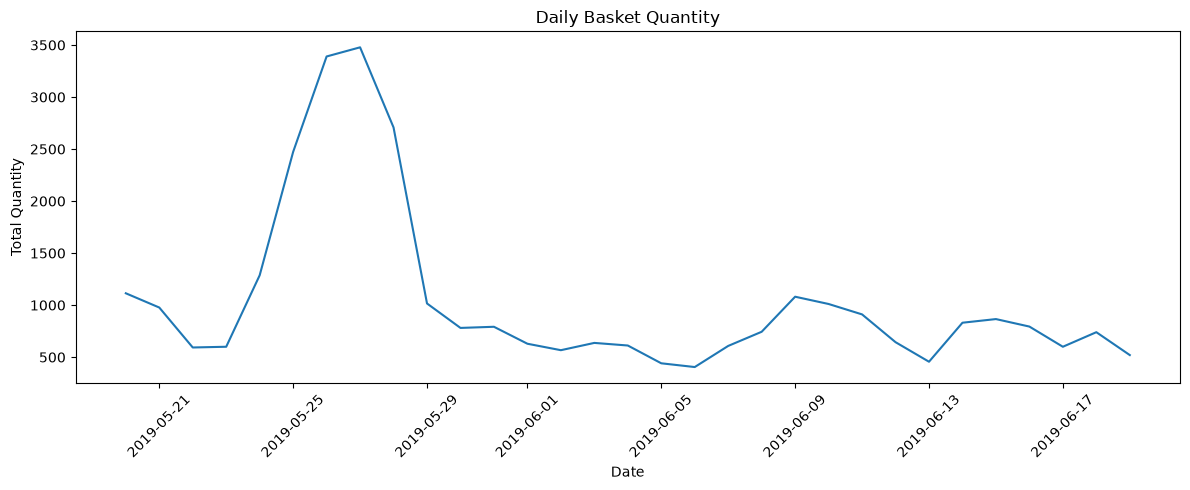

In [46]:
import matplotlib.pyplot as plt
import pandas as pd

daily_activity["activity_date"] = pd.to_datetime(
    daily_activity["activity_date"]
)

plt.figure(figsize=(12, 5))

plt.plot(
    daily_activity["activity_date"],
    daily_activity["total_quantity"]
)

plt.title("Daily Basket Quantity")
plt.xlabel("Date")
plt.ylabel("Total Quantity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Find the top 10 products using MySQL

In [51]:
query = """
SELECT
    product_id,
    SUM(basket_count) AS total_quantity
FROM basket_details
GROUP BY product_id
ORDER BY total_quantity DESC
LIMIT 10;
"""

top_products = pd.read_sql_query(query, engine)

display(top_products)

,product_id,total_quantity
0,43524799,69.0
1,31516269,59.0
2,39833031,50.0
3,46130148,36.0
4,34913531,28.0
5,3735903,27.0
6,40276011,27.0
7,6411072,23.0
8,42033035,23.0
9,39050110,22.0


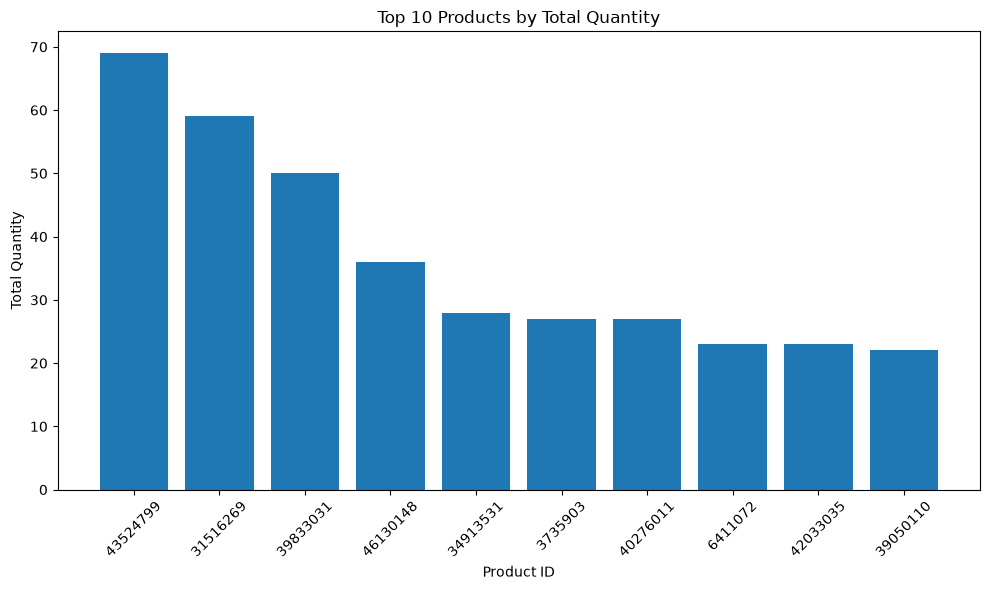

In [48]:
plt.figure(figsize=(10, 6))

plt.bar(
    top_products["product_id"].astype(str),
    top_products["total_quantity"]
)

plt.title("Top 10 Products by Total Quantity")
plt.xlabel("Product ID")
plt.ylabel("Total Quantity")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(
    "../data/processed/top_10_products.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Finding 1: Product 43524799 ranks first
Product 43524799 has the highest total quantity, at approximately 69 units. It is the leading product among the 10 products shown.

Finding 2: The top three products stand out
Products 43524799, 31516269, and 3833031 have approximate total quantities of 69, 59, and 50, respectively.
The fourth-ranked product has a total quantity of approximately 36. This suggests a noticeable drop between the third and fourth positions.

Finding 3: The lower-ranked products have similar quantities
Products ranked sixth and seventh each have approximately 27 units. Products ranked eighth and ninth each have approximately 23 units.
This indicates that the quantities for several lower-ranked products are relatively close.

Finding 4: The leading product is ahead of the tenth-ranked product
The leading product has approximately 69 units, compared with approximately 22 for the tenth-ranked product. The leading product's recorded quantity is therefore about three times as high.
Important: These results show recorded quantities, not product revenue, profit, or popularity among distinct customers. We would need prices, costs, or customer-level analysis to answer those other questions.

In [53]:
from sqlalchemy import text

with engine.connect() as connection:
    customer_count = connection.execute(
        text("SELECT COUNT(*) FROM customer_details")
    ).scalar_one()

    basket_count = connection.execute(
        text("SELECT COUNT(*) FROM basket_details")
    ).scalar_one()

print("Customers in MySQL:", customer_count)
print("Basket records in MySQL:", basket_count)

Customers in MySQL: 20000
Basket records in MySQL: 15000


In [54]:
import pandas as pd
from pathlib import Path

PROCESSED_DIR = Path("../data/processed")

customers_csv = pd.read_csv(
    PROCESSED_DIR / "customers_cleaned.csv"
)

baskets_csv = pd.read_csv(
    PROCESSED_DIR / "baskets_cleaned.csv"
)

print("Customers in cleaned CSV:", len(customers_csv))
print("Customers in MySQL:", customer_count)

print("Basket records in cleaned CSV:", len(baskets_csv))
print("Basket records in MySQL:", basket_count)

print("\nValidation results:")

print(
    "Customer row counts match:",
    len(customers_csv) == customer_count
)

print(
    "Basket row counts match:",
    len(baskets_csv) == basket_count
)

Customers in cleaned CSV: 20000
Customers in MySQL: 20000
Basket records in cleaned CSV: 15000
Basket records in MySQL: 15000

Validation results:
Customer row counts match: True
Basket row counts match: True


In [55]:
customer_quality_query = """
SELECT
    COUNT(*) AS total_rows,
    SUM(customer_id IS NULL) AS missing_customer_ids,
    SUM(customer_age IS NULL) AS missing_ages,
    SUM(sex IS NULL) AS missing_sex,
    SUM(tenure IS NULL) AS missing_tenure
FROM customer_details;
"""

customer_quality = pd.read_sql_query(
    customer_quality_query,
    engine
)

display(customer_quality)

,total_rows,missing_customer_ids,missing_ages,missing_sex,missing_tenure
0,20000,0.0,6707.0,0.0,0.0


In [56]:
basket_quality_query = """
SELECT
    COUNT(*) AS total_rows,
    SUM(customer_id IS NULL) AS missing_customer_ids,
    SUM(product_id IS NULL) AS missing_product_ids,
    SUM(basket_date IS NULL) AS missing_basket_dates,
    SUM(basket_count IS NULL) AS missing_basket_counts
FROM basket_details;
"""

basket_quality = pd.read_sql_query(
    basket_quality_query,
    engine
)

display(basket_quality)

,total_rows,missing_customer_ids,missing_product_ids,missing_basket_dates,missing_basket_counts
0,15000,0.0,0.0,0.0,0.0
